# Fully Connected Network (CIFAR-10 Dataset)

## Imports

In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.callbacks import EarlyStopping

import numpy as np
import matplotlib.pyplot as plt
from keras import backend as K
print(K.backend())

tensorflow


## Data preprocessing

The images are 32x32 pixels and contain 3 channels (RGB).
Each image is converted into a one-dimensional vector of 3072 elements (32 × 32 × 3).
Pixel values are normalized to the 0–1 scale, so that the model can learn more effectively and minimize numerical issues.
The test and validation data are separated using the `validation_split` parameter.
The target variable is not one-hot encoded, because we use the `SparseCategoricalCrossentropy` loss, which directly supports integer class labels (0–9).


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# pixel values normalization to the 0–1 scale
x_train = x_train.reshape(50000, 3072).astype("float32") / 255
x_test = x_test.reshape(10000, 3072).astype("float32") / 255

## Model architecture

The model uses several fully connected Dense layers with ReLU activations to introduce non-linearity.

- The first hidden layer contains 1024 neurons
- The second hidden layer: 256 neurons

The final layer is a 10-neuron softmax layer, which produces a probability distribution across the ten CIFAR-10 classes.

The model uses the Adam optimizer and SparseCategoricalCrossentropy loss, which are well suited for multiclass classification tasks.

The model uses two hidden layers (1024 and 256 neurons), balancing capacity and generalization.
The first layer captures complex nonlinear features, while the second compresses them before classification. After both hidden layers, there is a Dropout regularizer which prevents overfitting.

In [3]:
model = Sequential([
    Input(shape=(3072,)),
    Dense(1024, activation="relu"),
    Dropout(0.2),
    Dense(256, activation="relu"),
    Dropout(0.1),
    Dense(10, activation="softmax")
])

> resources to choose number of hidden layers and neurons:
> - https://stats.stackexchange.com/questions/181/how-to-choose-the-number-of-hidden-layers-and-nodes-in-a-feedforward-neural-netw
> - https://stats.stackexchange.com/questions/360692/what-is-the-optimal-number-of-neurons-in-fully-connected-layer-in-cnn

In [4]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 1024)                │       3,146,752 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         262,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,411,722 (13.01 MB)

 Trainable params: 3,411,722 (13.01 MB)

 Non-trainable params: 0 (0.00 B)

Model compilation (how the model will learn). The learning rate of the optimizer is set to 0.001, which is also the default for Adam.

In [5]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"],
)

## Model training

The model is trained for 100 epochs with a batch size of 256 and a validation split of 20%. The batch size was proven to give better results than, for instance, 64, 128 or 512. Training and validation loss are plotted to visualize the model's learning progress. The callback function stops the training when validation loss hasn't improved in the last 10 epochs.

In [6]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10)
history = model.fit(x_train, y_train, batch_size=256, epochs=100, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.2513 - loss: 2.1032 - val_accuracy: 0.3338 - val_loss: 1.8519
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.3494 - loss: 1.8048 - val_accuracy: 0.3548 - val_loss: 1.7843
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.3796 - loss: 1.7319 - val_accuracy: 0.3995 - val_loss: 1.7025
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.3963 - loss: 1.6837 - val_accuracy: 0.4174 - val_loss: 1.6450
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.4137 - loss: 1.6428 - val_accuracy: 0.4255 - val_loss: 1.6224
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.4286 - loss: 1.6106 - val_accuracy: 0.4413 - val_loss: 1.5877
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.4288 - loss: 1.6031 - val_accuracy: 0.4472 - val_loss: 1.5681
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.4362 - loss: 1.5738 - 

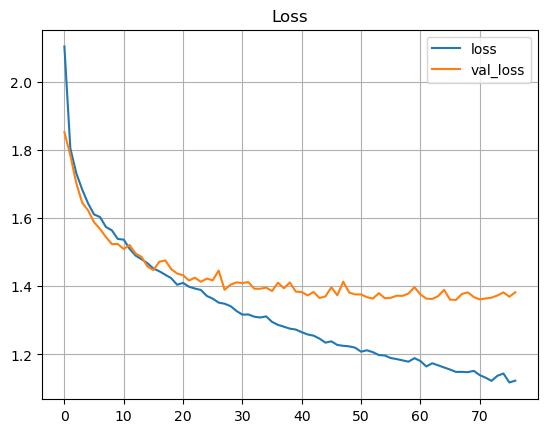

In [7]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.legend(["loss", "val_loss"])
plt.title("Loss")
plt.grid()
plt.show()

In [8]:
test_scores = model.evaluate(x_test, y_test, verbose=2)
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

313/313 - 1s - 2ms/step - accuracy: 0.5218 - loss: 1.3650
Test loss: 1.3649606704711914
Test accuracy: 0.5217999815940857


## Training and validation curves

The training and validation loss curves show a steady decrease throughout the process. Both losses drop rapidly during the first 10 to 15 epochs as the model quickly learns basic features, but then gradually levels off. 
Althought the training loss continues to decrease faster than the validation loss, the gap between them remains moderate, indicating that the model generalizes reasonably well and does not overfit severely.

Accuracy curves support this observation. Training accuracy increases steadily from 0,25 to 0,60, while validation accuracy improves rapidly and then stablilizes around 0,50 after around 20 to 25 epochs. After this point the validation accuracy stops improving while training accurasy still rises slightly. A sign of mild overfitting. 


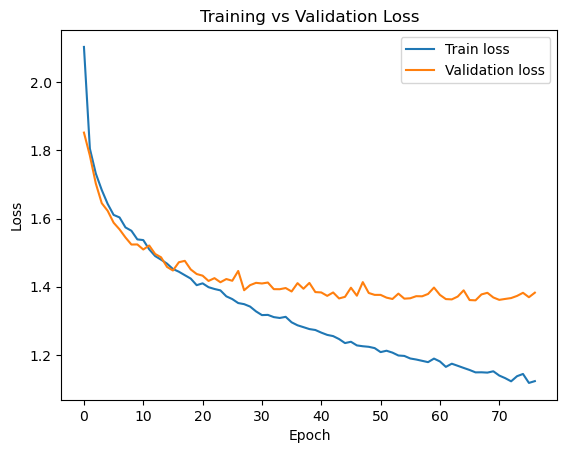

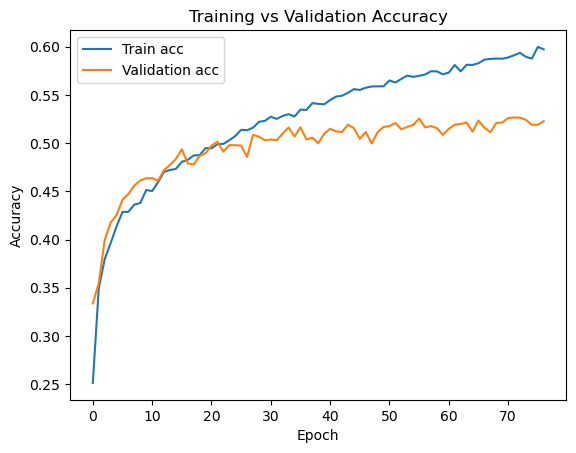

In [9]:
import matplotlib.pyplot as plt

# Loss-käyrät
plt.figure()
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

# Accuracy-käyrät
plt.figure()
plt.plot(history.history["accuracy"], label="Train acc")
plt.plot(history.history["val_accuracy"], label="Validation acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

The FCN achieved a test accuracy of approximately 51-52% and a test loss of 1,36-1,38 on the CIFAR-10 test set. 
This result falls withing the realistic target range defined for the model. 
Dropout likely contributed to better generalization by preventing the model from memorizing training data.

In [10]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

Test accuracy: 0.522
Test loss: 1.365


## Confusion Matrix and Classification Report
The confusion matrix shows that the FCN achieves reasonable performance on certain classes but struggles with others.
Best performing classes are automobile, ship and truck, which reach F1-scores of 0,57-0,65. However these categories have distinctive shapes and colors in the dataset, making them easier for the model to recognize even without convolutional layers.

In contrast the model performs poorly on more complex classes such as bird, cat and dog. Here the F1-scores remain below 0,50.
FCN cannot capture spatial patterns effetively, unlike a CNN. 

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


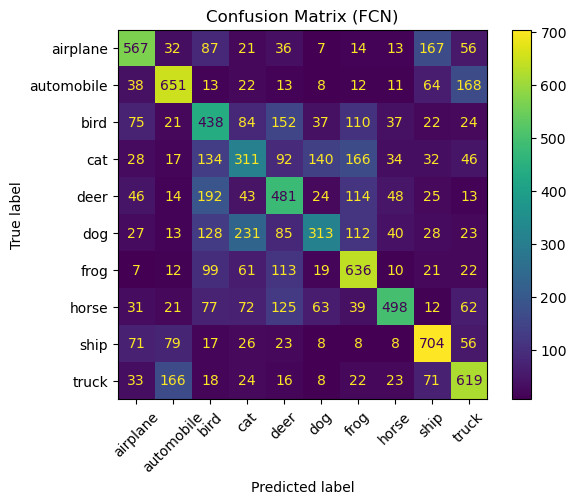

              precision    recall  f1-score   support

    airplane      0.614     0.567     0.590      1000
  automobile      0.635     0.651     0.643      1000
        bird      0.364     0.438     0.398      1000
         cat      0.347     0.311     0.328      1000
        deer      0.423     0.481     0.450      1000
         dog      0.499     0.313     0.385      1000
        frog      0.516     0.636     0.570      1000
       horse      0.690     0.498     0.578      1000
        ship      0.614     0.704     0.656      1000
       truck      0.568     0.619     0.593      1000

    accuracy                          0.522     10000
   macro avg      0.527     0.522     0.519     10000
weighted avg      0.527     0.522     0.519     10000



In [16]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Ennusteet
y_pred = np.argmax(model.predict(x_test), axis=1).reshape(-1)
y_true = y_test.reshape(-1)

# Sekamatriksi
cm = confusion_matrix(y_true, y_pred)
labels = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=45)
plt.title("Confusion Matrix (FCN)")
plt.show()

# Luokitteluraportti
print(classification_report(y_true, y_pred, target_names=labels, digits=3))

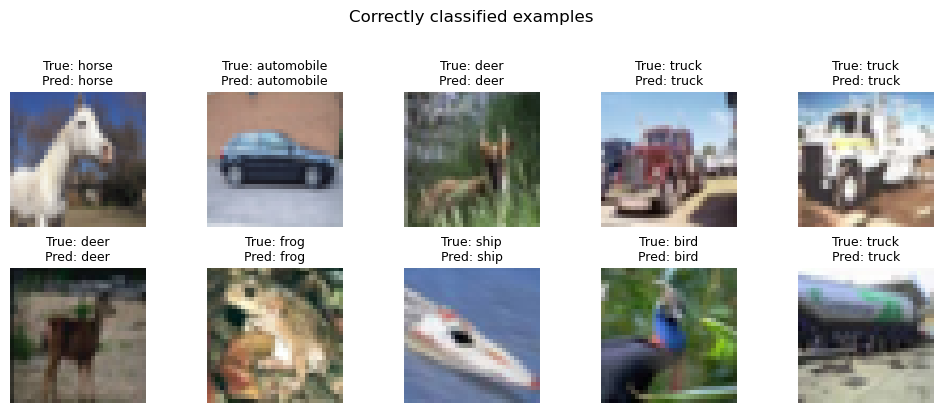

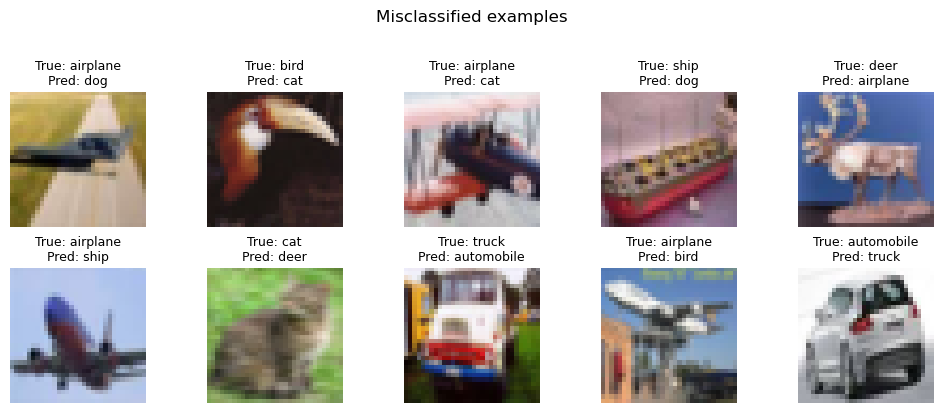

In [17]:
import random

# Etsitään indeksit
correct_idx = np.where(y_pred == y_true)[0]
incorrect_idx = np.where(y_pred != y_true)[0]

def show_examples(idxs, title, n=10):
    cols = 5
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(cols * 2.0, rows * 2.0))
    plt.suptitle(title, fontsize=12, y=1.02)

    for i, idx in enumerate(random.sample(list(idxs), n)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(x_test[idx].reshape(32, 32, 3))
        true_label = labels[y_true[idx]]
        pred_label = labels[y_pred[idx]]
        
        plt.title(f"True: {true_label}\nPred: {pred_label}",
                   fontsize=9, pad=5)
        plt.axis("off")

    plt.tight_layout()
    plt.show()
        

show_examples(correct_idx, "Correctly classified examples")
show_examples(incorrect_idx, "Misclassified examples")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


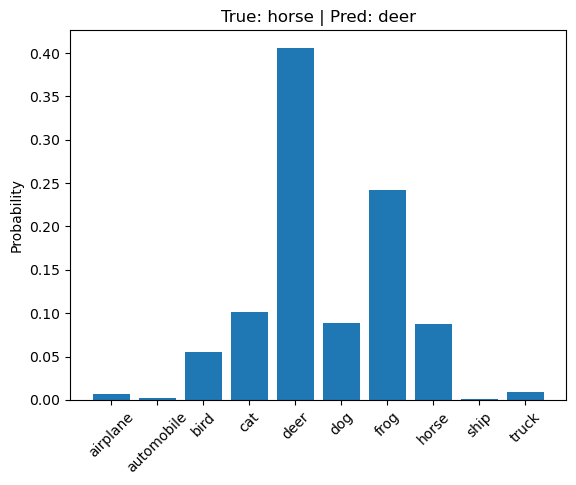

In [18]:
idx = random.randint(0, len(x_test))
probs = model.predict(x_test[idx:idx+1])[0]

plt.bar(range(10), probs)
plt.xticks(range(10), labels, rotation=45)
plt.title(f"True: {labels[y_true[idx]]} | Pred: {labels[np.argmax(probs)]}")
plt.ylabel("Probability")
plt.show()

In [15]:
print("Total parameters:", model.count_params())

Total parameters: 3411722


## Evaluation

The fully connected network (FCN) achieved a test accuracy of 50-52%, which falls within the realistic target range (50–55%) defined for this project.
The training and validation curves indicate stable learning behavior with mild overfitting, likely lessened by the inclusion of a dropout layer that helped the model generalize better to unseen data.
Both training and validation losses decreased steadily, indicating that the learning rate and model complexity were balanced.

Performance varies notably between classes. The model performs best on vehicle-related categories such as automobile, ship, and truck, where objects are more distinct in shape and color.
The FCN struggles with animal classes such as cat, dog, and bird, which share similar textures and backgrounds.
These misclassifications are expected, since the FCN flattens images into one-dimensional vectors and therefore loses important spatial information that would help distinguish between visually similar objects.

Overall the FCN provides a reasonable baseline model for CIFAR-10 classification tasks.
Results demonstrate that even a simple neural network can capture basic visual patterns, but that convolutional layers are essential for learning spatial hierarchies and achieving higher accuracy.
A CNN implementation is expected to outperform the FCN significantly (typically 75–85% accuracy) by leveraging local feature extraction and spatial invariance.
